Robert Shanahan - 23380039
Adam Downes - 23358173
Philip Roche - 23379707

Does our code work

Third party implementations used:
- Tensorflow agents: https://www.geeksforgeeks.org/machine-learning/reinforcement-learning-with-tensorflow-agents/
- Help: https://chloeewang.medium.com/using-deep-reinforcement-learning-to-play-atari-space-invaders-8d5159aa69ed
- Lecture: https://learn.ul.ie/d2l/le/lessons/91713/topics/1450952 

# Why Reinforcement Learning is the machine learning paradigm of choice for this task
- Training an ML agent to play *Space Invaders* requires reinforcement learning since each frame cannot be labeled as good or bad for supervised learning
- Reinforcement learning allows the agent to explore the environment and figure out the objective function through the environment giving it rewards based on its interations

# Gym Environment

In [37]:
"""
Install pre-requisite packages
"""
%pip install ale-py
import random

import gymnasium as gym
import ale_py
import pygame
import matplotlib.animation
import matplotlib.pyplot as plt
import tensorflow as tf
from tensorflow.keras import layers, models, optimizers
import numpy as np
from collections import deque

Note: you may need to restart the kernel to use updated packages.



[notice] A new release of pip is available: 26.0.1 -> 26.3
[notice] To update, run: python.exe -m pip install --upgrade pip


In [38]:
gym.register_envs(ale_py)

env = gym.make("ALE/SpaceInvaders-v5", render_mode="rgb_array") # load our space invaders as a rgb array
observation, info = env.reset() #reset the environment
pygame.init() # initialise pygame for rendering

(5, 0)

### Preprocessing of data

In [39]:
def plot_img(img, figsize=(4, 5.25)):
    plt.figure(figsize=figsize) 
    plt.imshow(img)
    plt.axis("off")
    return img

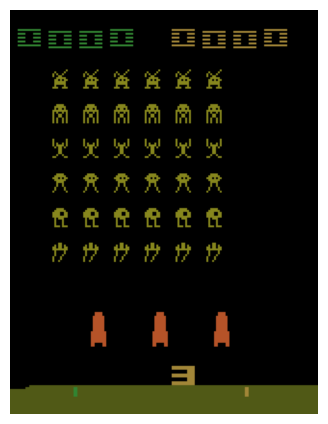

In [40]:
# Define a helper function for creating plots
def plot_environment(env, figsize=(4, 5.25)):
    plt.figure(figsize=figsize)
    img = env.render()
    plt.imshow(img)
    plt.axis("off")
    return img

plot_environment(env) # plot our initial image
plt.show()

In [41]:
envs = gym.envs.registry # envs is a dictionary of all atari games
envs["ALE/SpaceInvaders-v5"] # obtain information on space invaders

EnvSpec(id='ALE/SpaceInvaders-v5', entry_point='ale_py.env:AtariEnv', reward_threshold=None, nondeterministic=False, max_episode_steps=None, order_enforce=True, disable_env_checker=False, kwargs={'game': 'space_invaders', 'repeat_action_probability': 0.25, 'full_action_space': False, 'frameskip': 4, 'max_num_frames_per_episode': 108000}, namespace='ALE', name='SpaceInvaders', version=5, additional_wrappers=(), vector_entry_point='ale_py.vector_env:AtariVectorEnv')

In [42]:
img = env.render() # render a sample scene
img.shape  # height, width, channels (3 = Red, Green, Blue)

(210, 160, 3)

In [43]:
obs, info = env.reset(seed=42) # examine our observation scene with a reproducable seed 
obs

array([[[ 0,  0,  0],
        [ 0,  0,  0],
        [ 0,  0,  0],
        ...,
        [ 0,  0,  0],
        [ 0,  0,  0],
        [ 0,  0,  0]],

       [[ 0,  0,  0],
        [ 0,  0,  0],
        [ 0,  0,  0],
        ...,
        [ 0,  0,  0],
        [ 0,  0,  0],
        [ 0,  0,  0]],

       [[ 0,  0,  0],
        [ 0,  0,  0],
        [ 0,  0,  0],
        ...,
        [ 0,  0,  0],
        [ 0,  0,  0],
        [ 0,  0,  0]],

       ...,

       [[80, 89, 22],
        [80, 89, 22],
        [80, 89, 22],
        ...,
        [80, 89, 22],
        [80, 89, 22],
        [80, 89, 22]],

       [[80, 89, 22],
        [80, 89, 22],
        [80, 89, 22],
        ...,
        [80, 89, 22],
        [80, 89, 22],
        [80, 89, 22]],

       [[80, 89, 22],
        [80, 89, 22],
        [80, 89, 22],
        ...,
        [80, 89, 22],
        [80, 89, 22],
        [80, 89, 22]]], shape=(210, 160, 3), dtype=uint8)

In [44]:
env.action_space # examine number of possible actions

Discrete(6)

In [45]:
env.unwrapped.get_action_meanings() # obtain action meanings

['NOOP', 'FIRE', 'RIGHT', 'LEFT', 'RIGHTFIRE', 'LEFTFIRE']

In [68]:
def preprocess_state(img):
    img = tf.image.resize(img, (84, 84))
    img = tf.image.rgb_to_grayscale(img)
    img = tf.cast(img, tf.float32) / 255
    return img

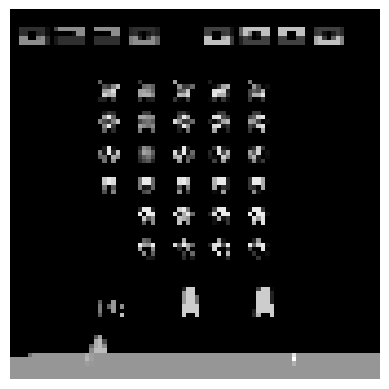

In [69]:
img = env.render()
gray_img = preprocess_state(img)
plt.imshow(tf.squeeze(gray_img), cmap="gray")  # drop the channel dim, use a grey colour map
plt.axis('off')
plt.show()


In [70]:
img.shape

(210, 160, 3)

### Network Structure

#### Frame Stacking

In [71]:
def combine_images(img1, img2, m=4):
    img1, img2 = np.squeeze(img1), np.squeeze(img2)
    if img1.ndim == 3 and img1.shape[2] == m:                     # existing stack (H, W, m)
        im = np.append(img1[:, :, 1:], img2[:, :, None], axis=2)  # drop oldest, add newest
    else:                                                         # first frame (H, W)
        im = np.stack([img1] * m, axis=2)
    return tf.expand_dims(im, 0)                                  # (1, H, W, m)

### Implementation

In [72]:
gray_img.shape

TensorShape([84, 84, 1])

In [73]:
env.action_space.n

np.int64(6)

In [ ]:
class DQN:
    def __init__(
        self,
        env,
        height,
        width,
        channels,
        action_size,
        epochs,
        epsilon,
        epsilon_decay,
        epsilon_min,
        threshold,
        alpha,
        alpha_decay,
        gamma,
        seed=42,
    ):
        self.env = env
        self.action_size = action_size
        self.epochs = epochs
        self.epsilon = epsilon
        self.epsilon_decay = epsilon_decay
        self.epsilon_min = epsilon_min
        self.threshold = threshold
        self.memory = deque(maxlen=20_000)
        self.gamma = gamma
        self.model = self.build_model(
            height, width, channels, action_size, alpha, alpha_decay, seed
        )
        self.model_target = self.build_target_model()

    def build_model(self, height, width, channels, action_size, alpha, alpha_decay, seed):
        tf.random.set_seed(seed)  # extra code – ensures reproducibility on the CPU
        # input = (84,84,3)

        model = tf.keras.Sequential([
            layers.Input(shape=(height, width, channels)),
            layers.Conv2D(32, kernel_size=8, strides=4, activation='elu', padding='valid'),
            layers.Conv2D(64, kernel_size=4, strides=2, activation='elu', padding='valid'),
            #layers.MaxPooling2D(),
            layers.Conv2D(64, kernel_size=3, strides=1, activation='elu', padding='valid'),
            #layers.MaxPooling2D(),
            layers.Flatten(),
            layers.Dense(256, activation="elu"),
            layers.Dense(action_size, activation='linear')
        ])

        lr_schedule = optimizers.schedules.InverseTimeDecay(
            initial_learning_rate=alpha, decay_steps=1, decay_rate=alpha_decay
        )
        model.compile(loss=tf.keras.losses.Huber(), optimizer=optimizers.Adam(learning_rate=lr_schedule))

        return model

    def build_target_model(self):
        target = models.clone_model(self.model)
        target.set_weights(self.model.get_weights())
        return target

    def choose_action(self, state, epsilon=None): #epsilon is the probability of exploring a random action
        if epsilon is None:
            epsilon = self.epsilon
        if np.random.rand() < epsilon:
            return np.random.randint(self.action_size)  # random action
        else:
            Q_values = self.model(state, training=False)[0].numpy()
            return Q_values.argmax()  # optimal action according to the DQN

    def replay(self, batch_size, memory):
        if len(memory) < batch_size:
            return
        minibatch = random.sample(memory, batch_size)
        states = np.concatenate([s for s, _, _, _, _ in minibatch])
        next_states = np.concatenate([n for _, _, _, n, _ in minibatch])
        q = self.model.predict(states, verbose=0)
        q_next = self.model_target.predict(next_states, verbose=0)
        for j, (_, action, reward, _, done) in enumerate(minibatch):
            q[j][action] = reward if done else reward + self.gamma * np.max(q_next[j])
        # backpropagation
        self.model.fit(states, q, verbose=0)
            
    def remember(self, state, action, reward, next_state, done):
        return self.memory.append((state, action, reward, next_state, done))
        
    def train(self):
        scores = deque(maxlen=100)
        avg_scores = []
        step = 0
        for e in range(self.epochs):
            obs, info = self.env.reset()
            state = preprocess_state(obs)
            state = combine_images(state, state)
            done = False
            i = 0
            while not done:
                action = self.choose_action(state)
                next_state, reward, terminated, truncated, info = self.env.step(action)
                done = (terminated or truncated)
                next_state = preprocess_state(next_state)
                next_state = combine_images(state, next_state)
                #print(next_state.shape)
                # storing terminated instead of done is slightly more correct
                # we changes reward to np.sign(reward) so it only remembers  the sign instead of the value
                self.remember(state, action, np.sign(reward), next_state, done) 
                state = next_state
                self.epsilon = max(self.epsilon_min, self.epsilon_decay * self.epsilon)
                i += reward
                step += 1
                if step > 5000 and step % 4 == 0:
                    self.replay(32, self.memory)
                if step % 1000 == 0:
                    self.model_target.set_weights(self.model.get_weights())

            #while loop finished
            scores.append(i)
            mean_score = np.mean(scores)
            avg_scores.append(mean_score)
            if mean_score >= self.threshold:
                print('Solved after {} trials ✔'.format(e))
                return avg_scores
            if e % 5 == 0:
                print('[Episode {}] - Average Score: {}.'.format(e,mean_score))
                
        return avg_scores

In [ ]:
N_OUTPUTS = 6
EPOCHS = 100
EPSILON = 0.99
EPSILON_DECAY = 0.9999
THRESHOLD = 9000
EPSILON_MIN = 0.05
LEARNING_RATE = 0.0001
ALPHA_DECAY = 0
GAMMA = 0.99

In [66]:
dqn = DQN(
    env=env,
    height=84,
    width=84,
    channels=4,
    action_size=N_OUTPUTS,
    epochs=EPOCHS,
    epsilon=EPSILON,
    epsilon_decay=EPSILON_DECAY,
    epsilon_min=EPSILON_MIN,
    threshold=THRESHOLD,
    alpha=LEARNING_RATE,
    alpha_decay=ALPHA_DECAY,
    gamma=GAMMA
)

In [67]:
avg_scores = dqn.train()
plt.plot(avg_scores)
plt.xlabel('Episode')
plt.ylabel('Avg score')
plt.show()

[Episode 0] - Average Score: 75.0.


KeyboardInterrupt: 

# Results

# Evaluation of Results

# Research

# Statement of Work

# Use of AI

## Prompt:
can you review the hyperparameters in rl_project.ipynb

## Answer
Looking for `rl_project.py` in the workspace.

Find files matching `**/*.py`

Read 
Completed with input: {
  "path": "c:\\Users\\RShanah2\\AppData\\Roaming\\Code\\agentSessionData\\db3b9299-11f9-46a1-9570-b7700d15ca6b\\attachments\\b9f11a03-1ac9-4464-9379-e9c3329e9477\\file_RL_project.ipynb"
}

Read 
Completed with input: {
  "path": "c:\\Users\\RShanah2\\OneDrive - Analog Devices, Inc\\Desktop\\college\\jj_project\\JJ_Proj\\rl_project.py"
}

Read 
Completed with input: {
  "path": "c:\\Users\\RShanah2\\OneDrive - Analog Devices, Inc\\Desktop\\college\\jj_project\\JJ_Proj\\main.py"
}

Read , lines 1 to 400
Completed with input: {
  "path": "c:\\Users\\RShanah2\\OneDrive - Analog Devices, Inc\\Desktop\\college\\jj_project\\JJ_Proj\\rl_project.py",
  "view_range": [
    1,
    400
  ],
  "forceReadLargeFiles": true
}

The script exists. I'll check whether there are logs from a previous run so the review can use real numbers.

Find files matching `**/runs/**/*.{log,csv,json}`

I reviewed `rl_project.py`. There are no saved runs yet, so this is based on reading the code. Compared with the notebook, the settings are much better: longer training, slower exploration decay, a standard warm-up and target update. However, **the replay memory size of 500,000 will make the run crash** unless you also change how states are stored.

## 🔴 Critical: replay memory size

Each saved step holds two `(1, 84, 84, 4)` float32 frame stacks, about **226 KB per step**:

| Memory filled to | RAM needed |
|---|---|
| 50,000 (the point where learning starts) | **about 11 GB** |
| 500,000 (the `maxlen` you set) | **about 113 GB** |

On most machines, the run will run out of memory before learning even starts.

There's also a likely GPU problem. `combine_images` returns a TensorFlow tensor, and when a GPU is found TensorFlow will probably create those tensors on the GPU. If so, the whole replay memory sits in GPU memory, which would fill up even sooner.

**Fix:** store frame stacks as `uint8` NumPy arrays (4x smaller, and kept in normal RAM). Convert back to float only when sampling a batch:

```python
def remember(self, state, action, reward, next_state, done):
    to_u8 = lambda s: (np.asarray(s) * 255).astype(np.uint8)
    self.memory.append((to_u8(state), action, reward, to_u8(next_state), done))
```

```python
states = np.concatenate([s for s, *_ in minibatch]).astype(np.float32) / 255
next_states = np.concatenate([m[3] for m in minibatch]).astype(np.float32) / 255
```

Even with `uint8`, each step is about 56 KB, so 500k would still need about 28 GB. **Set `maxlen` to about 100,000–150,000** (about 5.6–8.5 GB). That's plenty for a run of this length.

## Hyperparameter review

| Param | Value | Verdict |
|---|---|---|
| `EPOCHS` | 1000 episodes | ✅ Reasonable for a project. At about 600–900 steps per episode, that's about 0.6–0.9M steps and roughly 150–200k gradient updates. Expect clear improvement over random play, not paper-level scores. |
| `EPSILON_DECAY` | 0.99999 per step | ✅ Good. Epsilon reaches 0.05 at about 300k steps. It still decays during the warm-up, so it's about **0.60 when learning starts at step 50k**, which is fine. |
| `EPSILON` / `EPSILON_MIN` | 0.99 / 0.05 | ✅ Standard |
| `LEARNING_RATE` | 1e-4 (Adam) | ✅ Good |
| `ALPHA_DECAY` | 0 | ✅ Keep it at 0. Any non-zero value with `decay_steps=1` shrinks the learning rate very quickly. |
| `GAMMA` | 0.99 | ✅ Standard |
| Warm-up | 50,000 steps | ✅ Matches the original DQN paper, but it's also what causes the 11 GB problem above. Use 20k–50k. |
| Train every / batch size | every 4 steps / 32 | ✅ Standard |
| Target update | every 10,000 steps | ✅ Fine. That's 2,500 gradient updates between syncs. |
| `THRESHOLD` | 9000 | ⚪ Harmless because it will never trigger, so all 1000 episodes always run. Set it to about 1000, or remove it. |
| Replay memory | 500,000 | 🔴 See above. Use 100k–150k stored as `uint8`. |

## Things that affect run time

1. **Videos every 5 episodes** means about 200 training videos, and each one slows its episode down. Every 50 episodes is enough (`ep % 50 == 0`).
2. **`replay()` uses `model.predict()` twice and `model.fit()` once per update.** These calls have a lot of fixed overhead, and there are about 200k updates. This could add many hours to the run. Faster versions:
   ```python
   q = self.model(states, training=False).numpy()
   q_next = self.model_target(next_states, training=False).numpy()
   loss = self.model.train_on_batch(states, q)
   ```
3. **Evaluation with `epsilon=0.0`:** a purely greedy agent can get stuck repeating one move. `epsilon=0.05` is the standard for evaluation and gives scores that are easier to compare.

**Bottom line:** the hyperparameters are sound. Store frames as `uint8` and lower the memory to about 100k, or the run won't finish. The `predict`→direct call change and fewer videos will save a lot of time. I can make these edits if you'd like.Lhooking for `rl_project.py` in the workspace.

Find files matching `**/*.py`

Read 
Completed with input: {
  "path": "c:\\Users\\RShanah2\\AppData\\Roaming\\Code\\agentSessionData\\db3b9299-11f9-46a1-9570-b7700d15ca6b\\attachments\\b9f11a03-1ac9-4464-9379-e9c3329e9477\\file_RL_project.ipynb"
}

Read 
Completed with input: {
  "path": "c:\\Users\\RShanah2\\OneDrive - Analog Devices, Inc\\Desktop\\college\\jj_project\\JJ_Proj\\rl_project.py"
}

Read 
Completed with input: {
  "path": "c:\\Users\\RShanah2\\OneDrive - Analog Devices, Inc\\Desktop\\college\\jj_project\\JJ_Proj\\main.py"
}

Read , lines 1 to 400
Completed with input: {
  "path": "c:\\Users\\RShanah2\\OneDrive - Analog Devices, Inc\\Desktop\\college\\jj_project\\JJ_Proj\\rl_project.py",
  "view_range": [
    1,
    400
  ],
  "forceReadLargeFiles": true
}

The script exists. I'll check whether there are logs from a previous run so the review can use real numbers.

Find files matching `**/runs/**/*.{log,csv,json}`

I reviewed `rl_project.py`. There are no saved runs yet, so this is based on reading the code. Compared with the notebook, the settings are much better: longer training, slower exploration decay, a standard warm-up and target update. However, **the replay memory size of 500,000 will make the run crash** unless you also change how states are stored.

## 🔴 Critical: replay memory size

Each saved step holds two `(1, 84, 84, 4)` float32 frame stacks, about **226 KB per step**:

| Memory filled to | RAM needed |
|---|---|
| 50,000 (the point where learning starts) | **about 11 GB** |
| 500,000 (the `maxlen` you set) | **about 113 GB** |

On most machines, the run will run out of memory before learning even starts.

There's also a likely GPU problem. `combine_images` returns a TensorFlow tensor, and when a GPU is found TensorFlow will probably create those tensors on the GPU. If so, the whole replay memory sits in GPU memory, which would fill up even sooner.

**Fix:** store frame stacks as `uint8` NumPy arrays (4x smaller, and kept in normal RAM). Convert back to float only when sampling a batch:

```python
def remember(self, state, action, reward, next_state, done):
    to_u8 = lambda s: (np.asarray(s) * 255).astype(np.uint8)
    self.memory.append((to_u8(state), action, reward, to_u8(next_state), done))
```

```python
states = np.concatenate([s for s, *_ in minibatch]).astype(np.float32) / 255
next_states = np.concatenate([m[3] for m in minibatch]).astype(np.float32) / 255
```

Even with `uint8`, each step is about 56 KB, so 500k would still need about 28 GB. **Set `maxlen` to about 100,000–150,000** (about 5.6–8.5 GB). That's plenty for a run of this length.

## Hyperparameter review

| Param | Value | Verdict |
|---|---|---|
| `EPOCHS` | 1000 episodes | ✅ Reasonable for a project. At about 600–900 steps per episode, that's about 0.6–0.9M steps and roughly 150–200k gradient updates. Expect clear improvement over random play, not paper-level scores. |
| `EPSILON_DECAY` | 0.99999 per step | ✅ Good. Epsilon reaches 0.05 at about 300k steps. It still decays during the warm-up, so it's about **0.60 when learning starts at step 50k**, which is fine. |
| `EPSILON` / `EPSILON_MIN` | 0.99 / 0.05 | ✅ Standard |
| `LEARNING_RATE` | 1e-4 (Adam) | ✅ Good |
| `ALPHA_DECAY` | 0 | ✅ Keep it at 0. Any non-zero value with `decay_steps=1` shrinks the learning rate very quickly. |
| `GAMMA` | 0.99 | ✅ Standard |
| Warm-up | 50,000 steps | ✅ Matches the original DQN paper, but it's also what causes the 11 GB problem above. Use 20k–50k. |
| Train every / batch size | every 4 steps / 32 | ✅ Standard |
| Target update | every 10,000 steps | ✅ Fine. That's 2,500 gradient updates between syncs. |
| `THRESHOLD` | 9000 | ⚪ Harmless because it will never trigger, so all 1000 episodes always run. Set it to about 1000, or remove it. |
| Replay memory | 500,000 | 🔴 See above. Use 100k–150k stored as `uint8`. |

## Things that affect run time

1. **Videos every 5 episodes** means about 200 training videos, and each one slows its episode down. Every 50 episodes is enough (`ep % 50 == 0`).
2. **`replay()` uses `model.predict()` twice and `model.fit()` once per update.** These calls have a lot of fixed overhead, and there are about 200k updates. This could add many hours to the run. Faster versions:
   ```python
   q = self.model(states, training=False).numpy()
   q_next = self.model_target(next_states, training=False).numpy()
   loss = self.model.train_on_batch(states, q)
   ```
3. **Evaluation with `epsilon=0.0`:** a purely greedy agent can get stuck repeating one move. `epsilon=0.05` is the standard for evaluation and gives scores that are easier to compare.

**Bottom line:** the hyperparameters are sound. Store frames as `uint8` and lower the memory to about 100k, or the run won't finish. The `predict`→direct call change and fewer videos will save a lot of time. I can make these edits if you'd like.

# Videos and Plots

# References